# D. PRO «Клиент под защитой» — исследование данных и проверка гипотез

Ноутбук воспроизводит основные анализы, из которых сложилась финальная модель (LightGBM, усреднение по 30 сидам, `train.py`).
Это сжатая версия: числа можно перепроверить прямо здесь, всё считается только по `hard_train.csv`
(`hard_test.csv` используется лишь в проверке структуры и сдвига признаков, метки теста нам неизвестны).
Положите ноутбук рядом с `train.py`; данные ищутся в `.`, `..`, `data`, либо в переменной окружения `DATA_DIR`. Время работы ≈ 5 минут.

**Порядок:** 1) данные и их структура → 2) цель и ключевые признаки → 3) гипотеза «линейная модель на logit-шкале» →
4) нелинейность и взаимодействия → 5) утечки и сдвиг → 6) выбор гиперпараметров бустинга → 7) итог и проверка весов.

In [9]:
import os, sys, time, warnings
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import KFold, StratifiedKFold, cross_val_predict
from sklearn.metrics import roc_auc_score
import lightgbm as lgb

def find_data():
    for c in [os.environ.get('DATA_DIR'), '.']:
        if c and os.path.exists(os.path.join(c, 'hard_train.csv')):
            return c
    raise FileNotFoundError('Положите hard_train.csv и hard_test.csv рядом с ноутбуком или задайте DATA_DIR')
DATA_DIR = find_data()
sys.path.insert(0, os.getcwd())
from train import make_frame, PARAMS, CATS          # та же предобработка и параметры, что у финальной модели

BLUE, ORANGE, INK, MUTED, SURF = '#2a78d6', '#eb6834', '#0b0b0b', '#52514e', '#fcfcfb'
plt.rcParams.update({'figure.facecolor': SURF, 'axes.facecolor': SURF, 'axes.edgecolor': '#c9c8c2', 'axes.spines.top': False,
    'axes.spines.right': False, 'axes.grid': True, 'grid.color': '#e8e7e2', 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'text.color': INK, 'axes.labelcolor': MUTED, 'xtick.color': MUTED, 'ytick.color': MUTED, 'font.size': 10,
    'axes.titlesize': 11, 'axes.titlelocation': 'left', 'figure.dpi': 110, 'lines.linewidth': 2})
rmse = lambda p, t: float(np.sqrt(np.mean((np.asarray(p) - np.asarray(t)) ** 2)))
sig = lambda t: 1 / (1 + np.exp(-t))
GX, GW = np.polynomial.hermite_e.hermegauss(40); GW = GW / GW.sum()
smooth = lambda f, s: 100 * (sig(np.asarray(f)[:, None] + s * GX[None, :]) * GW[None, :]).sum(1)   # E[100*sigmoid(f + s*N(0,1))]

tr = pd.read_csv(f'{DATA_DIR}/hard_train.csv'); te = pd.read_csv(f'{DATA_DIR}/hard_test.csv')
y = tr.protection_score.values
print('данные из:', os.path.abspath(DATA_DIR))

данные из: d:\RuCode2026\D_PRO\solution\closed_test\FINAL


## 1. Данные и их структура

In [10]:
print('train', tr.shape, '| test', te.shape)
print('ID train:', tr.customer_id.min(), '…', tr.customer_id.max(), '| ID test:', te.customer_id.min(), '…', te.customer_id.max())
print('пересечение ID train/test:', len(set(tr.customer_id) & set(te.customer_id)), '| дубликаты строк признаков в train:', tr.drop(columns=['customer_id', 'protection_score']).duplicated().sum())
miss = pd.DataFrame({'train': tr.isna().mean(), 'test': te.isna().mean()})
display(miss[(miss.train > 0) | (miss.test > 0)].round(3))

train (10000, 61) | test (2000, 60)
ID train: CUST100000 … CUST109999 | ID test: CUST110000 … CUST111999
пересечение ID train/test: 0 | дубликаты строк признаков в train: 0


,train,test
average_claim_cost,0.396,0.402
car_value,0.410,0.416
house_value,0.467,0.461


In [11]:
# Структурные пропуски и производные признаки: проверяем, что они согласованы
ins = ['life_insurance', 'property_insurance', 'health_insurance', 'travel_insurance', 'car_insurance', 'gadget_insurance', 'cyber_protection', 'identity_protection']
cf = (tr.number_of_claims / tr.years_with_company.replace(0, np.nan)).fillna(0)
print('insurance_products == сумма 8 бинарных продуктов :', (tr[ins].sum(1) == tr.insurance_products).mean())
print('claim_frequency == обращения / срок обслуживания  :', np.isclose(cf, tr.claim_frequency, atol=0.01).mean())
print('average_claim_cost пуст  <=>  number_of_claims == 0 :', (tr.average_claim_cost.isna() == (tr.number_of_claims == 0)).mean())
print('возраст - 18 >= years_with_company                 :', (tr.age - 18 >= tr.years_with_company).mean())
display(tr.groupby('wealth_segment').income.agg(['min', 'max']).round(0))

insurance_products == сумма 8 бинарных продуктов : 1.0
claim_frequency == обращения / срок обслуживания  : 1.0
average_claim_cost пуст  <=>  number_of_claims == 0 : 1.0
возраст - 18 >= years_with_company                 : 1.0


,min,max
wealth_segment,,
affluent,45001.0,119976.0
mass,12000.0,44999.0
premium,120001.0,334577.0
private,345139.0,346531.0


##### Вывод: пропуски house_value / car_value / average_claim_cost = «объекта нет» -> заполняем 0 и добавляем флаг *_na.

## 2. Целевая переменная и ключевые признаки

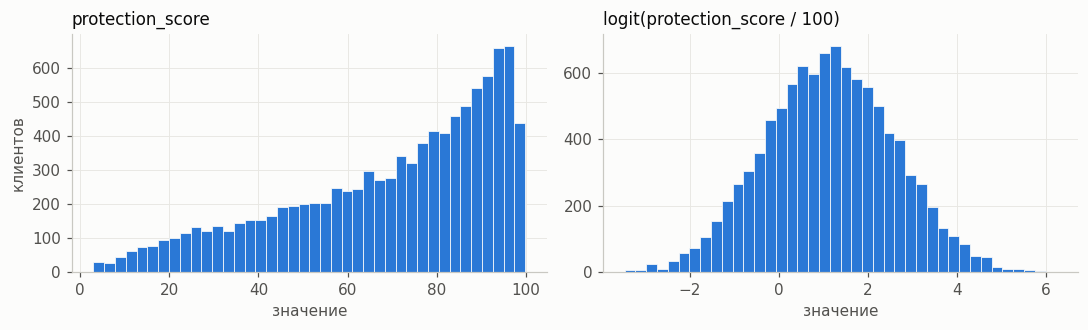

count    10000.00
mean        69.37
std         23.83
min          3.02
25%         53.40
50%         75.76
75%         89.45
max         99.81
асимметрия: y -0.77 | logit 0.01


In [12]:
p = np.clip(y / 100, 1e-3, 1 - 1e-3); z = np.log(p / (1 - p))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.1))
ax[0].hist(y, bins=40, color=BLUE, edgecolor=SURF, linewidth=0.5); ax[0].set_title('protection_score'); ax[0].set_xlabel('значение'); ax[0].set_ylabel('клиентов')
ax[1].hist(z, bins=40, color=BLUE, edgecolor=SURF, linewidth=0.5); ax[1].set_title('logit(protection_score / 100)'); ax[1].set_xlabel('значение')
plt.tight_layout(); plt.show()
print(pd.Series(y).describe().round(2).to_string()); print('асимметрия: y %.2f | logit %.2f' % (stats.skew(y), stats.skew(z)))

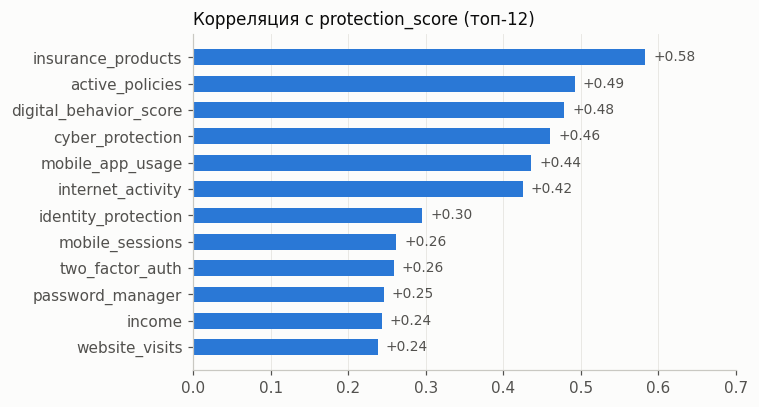

In [13]:
num = tr.select_dtypes('number').drop(columns='protection_score')
c = num.corrwith(tr.protection_score).sort_values(key=abs, ascending=False).head(12)[::-1]
fig, ax = plt.subplots(figsize=(7, 3.8)); ax.barh(c.index, c.values, color=BLUE, height=0.6); ax.axvline(0, color='#c9c8c2', lw=1)
for i, v in enumerate(c.values): ax.text(v + 0.01, i, f'{v:+.2f}', va='center', color=MUTED, fontsize=9)
ax.set_title('Корреляция с protection_score (топ-12)'); ax.grid(axis='y', visible=False); ax.set_xlim(0, 0.7); plt.tight_layout(); plt.show()

##### Лидеры — страховой портфель (insurance_products, active_policies, cyber_protection) и цифровое поведение.

## 3. Гипотеза: цель = 100·σ(линейная функция) + шум на logit-шкале
Если так, то регрессия на `logit(y/100)` должна объяснить почти всё, а прогноз по исходной шкале — `E[100·σ(f+ε)]`, а не `100·σ(f)`.
Сравниваем на 5-fold CV: бустинг на сырой цели, линейная модель с наивным прогнозом, линейная модель с поправкой на шум.

In [14]:
def linear_frame(df):
    D = pd.get_dummies(df.drop(columns=['customer_id', 'protection_score'], errors='ignore'), drop_first=True).astype(float)
    for c in ['house_value', 'car_value', 'average_claim_cost']:
        D[c + '_na'] = D[c].isna().astype(float); D[c] = D[c].fillna(0)
    return D
D = linear_frame(tr); Xf, cat_maps = make_frame(tr)
kf = KFold(5, shuffle=True, random_state=1)
o = {k: np.zeros(len(y)) for k in ['LightGBM на сырой цели (финальные параметры)', 'Ridge на logit, 100·σ(f)', 'Ridge на logit, E[100·σ(f+ε)]']}
f_oof = np.zeros(len(y)); sig_eps = []
for a, b in kf.split(D):
    mu, sd = D.iloc[a].mean(), D.iloc[a].std() + 1e-9
    m = RidgeCV(alphas=np.logspace(-1, 3, 10)).fit((D.iloc[a] - mu) / sd, z[a]); s = np.std(z[a] - m.predict((D.iloc[a] - mu) / sd)); sig_eps.append(s)
    f = m.predict((D.iloc[b] - mu) / sd); f_oof[b] = f
    o['Ridge на logit, 100·σ(f)'][b] = 100 * sig(f); o['Ridge на logit, E[100·σ(f+ε)]'][b] = smooth(f, s)
    o['LightGBM на сырой цели (финальные параметры)'][b] = lgb.LGBMRegressor(**PARAMS, random_state=0).fit(Xf.iloc[a], y[a]).predict(Xf.iloc[b])
tab = pd.Series({k: rmse(v, y) for k, v in o.items()}); tab['Константа (среднее)'] = y.std()
sigma = float(np.mean(sig_eps))
fl = np.sqrt(np.mean(((100 * sig(f_oof[:, None] + sigma * GX[None, :])) ** 2 * GW[None, :]).sum(1) - smooth(f_oof, sigma) ** 2))
display(tab.round(3).rename('CV RMSE').to_frame())
print(f'σ шума на logit-шкале ≈ {sigma:.3f}; теоретический минимум RMSE при чисто гауссовом шуме такой величины ≈ {fl:.2f}')
print('R² на logit-шкале: %.3f' % (1 - np.mean((z - f_oof) ** 2) / z.var()))

,CV RMSE
LightGBM на сырой цели (финальные параметры),10.512
"Ridge на logit, 100·σ(f)",10.233
"Ridge на logit, E[100·σ(f+ε)]",10.164
Константа (среднее),23.824


σ шума на logit-шкале ≈ 0.594; теоретический минимум RMSE при чисто гауссовом шуме такой величины ≈ 10.12
R² на logit-шкале: 0.831


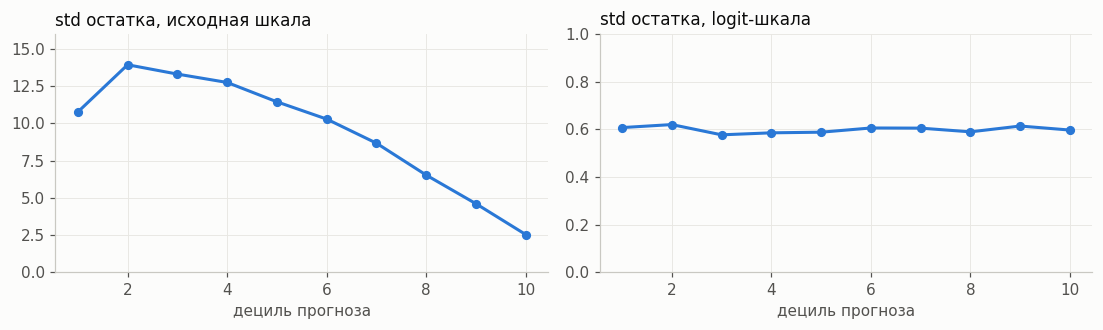

In [15]:
# Гетероскедастичность: разброс остатков по децилям прогноза. На logit-шкале он ровный, на исходной — «колокол».
q = pd.qcut(f_oof, 10, labels=False); res_y = y - smooth(f_oof, sigma); res_z = z - f_oof
sy = pd.Series(res_y).groupby(q).std(); sz = pd.Series(res_z).groupby(q).std()
fig, ax = plt.subplots(1, 2, figsize=(10, 3.1), sharex=True)
ax[0].plot(range(1, 11), sy.values, color=BLUE, marker='o', ms=5); ax[0].set_title('std остатка, исходная шкала'); ax[0].set_ylim(0, 16)
ax[1].plot(range(1, 11), sz.values, color=BLUE, marker='o', ms=5); ax[1].set_title('std остатка, logit-шкала'); ax[1].set_ylim(0, 1)
for a_ in ax: a_.set_xlabel('дециль прогноза')
plt.tight_layout(); plt.show()

##### Шум аддитивен и однороден на logit-шкале — отсюда «разный шум» для малозащищённых и защищённых клиентов на обычной шкале.

## 4. Есть ли нелинейность и взаимодействия сверх линейной модели?
Проверяем остатки линейной модели: все квадраты и парные произведения (≈3 тыс. проверок) с поправкой на множественные сравнения.

In [16]:
Dz = D.copy(); Dz = Dz.loc[:, Dz.std() > 0]; Xs = ((Dz - Dz.mean()) / Dz.std())
base = np.c_[np.ones(len(Xs)), Xs.values]; beta = np.linalg.lstsq(base, z, rcond=None)[0]; r0 = z - base @ beta; s0 = r0.std()
Q, _ = np.linalg.qr(base); cols = list(Xs.columns); out = []
def test(v, name):
    v = v - Q @ (Q.T @ v); n2 = v @ v
    if n2 > 1e-6: out.append((name, (v @ r0) / n2, (v @ r0) / np.sqrt(n2) / s0))
import itertools
for c in cols: test(Xs[c].values ** 2, c + '^2')
for a_, b_ in itertools.combinations(cols, 2): test(Xs[a_].values * Xs[b_].values, a_ + ' * ' + b_)
R = pd.DataFrame(out, columns=['член', 'коэф.', 't']).sort_values('t', key=abs, ascending=False)
thr = stats.norm.isf(0.025 / len(R))
print(f'проверено членов: {len(R)}; порог |t| с поправкой Бонферрони: {thr:.2f}; значимых: {(R.t.abs() > thr).sum()}')
print(f'|t| > 3: {(R.t.abs() > 3).sum()} (случайно ожидается ≈ {len(R) * 0.0027:.0f})')
display(R.head(6).round(3))

проверено членов: 3143; порог |t| с поправкой Бонферрони: 4.32; значимых: 0
|t| > 3: 13 (случайно ожидается ≈ 8)


,член,коэф.,t
1224,smartphone_age * city_type_rural,-0.022,-3.617
1327,life_insurance * days_since_last_login,0.020,3.399
196,occupation_risk * years_with_company,0.022,3.333
2565,customer_loyalty * crime_rate,0.020,3.297
313,years_with_company * customer_loyalty,-0.015,-3.227
476,financial_literacy * region_Ural,-0.019,-3.221


In [17]:
# Нелинейность на уровне моделей: глубокий бустинг на остатках линейной модели не улучшает остаток
res = np.zeros(len(y)); r_oof = z - f_oof
for a, b in KFold(5, shuffle=True, random_state=2).split(D):
    g = lgb.LGBMRegressor(n_estimators=300, learning_rate=0.02, num_leaves=15, min_child_samples=50, subsample=0.7, subsample_freq=1, verbose=-1, random_state=0).fit(Dz.iloc[a], r_oof[a])
    res[b] = g.predict(Dz.iloc[b])
print('std остатка linear logit: %.4f -> после GBM на остатках: %.4f' % (r_oof.std(), (r_oof - res).std()))

std остатка linear logit: 0.5992 -> после GBM на остатках: 0.6059


##### Вывод: на train сверх линейной модели сигнала не видно — но шум меток (≈10 RMSE) закрывает слабые эффекты, см. раздел 6.

## 5. Утечки и сдвиг распределений train → test

In [18]:
# Adversarial validation: отличает ли бустинг строки теста от строк train по признакам?
A = pd.concat([tr.drop(columns=['customer_id', 'protection_score']), te.drop(columns=['customer_id'])], ignore_index=True)
AF, _ = make_frame(A.assign(customer_id=0)); lab = np.r_[np.zeros(len(tr)), np.ones(len(te))]
pp = cross_val_predict(lgb.LGBMClassifier(n_estimators=200, learning_rate=0.05, num_leaves=15, verbose=-1, random_state=0), AF, lab,
                       cv=StratifiedKFold(5, shuffle=True, random_state=0), method='predict_proba')[:, 1]
print('AUC «train против test»: %.3f  (0.5 = различить нельзя)' % roc_auc_score(lab, pp))
# Порядок строк / ID: остатки не должны зависеть от номера клиента
idn = tr.customer_id.str[4:].astype(int).values
print('corr(остаток, ID) = %.3f; автокорреляция остатков по порядку строк (lag 1) = %.3f' % (np.corrcoef(r_oof, idn)[0, 1], np.corrcoef(r_oof[:-1], r_oof[1:])[0, 1]))
num_cols = [c for c in te.columns if c != 'customer_id' and tr[c].dtype.kind in 'if' and tr[c].nunique() > 10]
ks = pd.Series({c: stats.ks_2samp(tr[c].dropna(), te[c].dropna()).statistic for c in num_cols}).sort_values(ascending=False)
print('макс. статистика KS по числовым признакам: %.3f (%s)' % (ks.iloc[0], ks.index[0]))

AUC «train против test»: 0.512  (0.5 = различить нельзя)
corr(остаток, ID) = -0.033; автокорреляция остатков по порядку строк (lag 1) = -0.001
макс. статистика KS по числовым признакам: 0.048 (house_value)


## 6. Выбор гиперпараметров бустинга
Метки train сильно зашумлены, поэтому абсолютный CV-RMSE (≈ 10.5) почти не различает варианты. Но если шум не зависит от признаков,
**разность ошибок двух моделей на одних и тех же объектах** остаётся информативной. Сравниваем варианты парно с финальной конфигурацией:
положительное значение — вариант хуже.

,вариант,CV RMSE,ΔMSE к A,SE
0,colsample 0.6,10.516,-0.465,0.289
1,colsample 0.4,10.497,-0.862,0.404
2,7 листьев,10.549,0.237,0.317
3,31 лист,10.585,0.998,0.328
4,63 листа,10.683,3.086,0.471
5,350 деревьев,10.586,1.019,0.239
6,1400 деревьев,10.603,1.374,0.191
7,min_child 40,10.549,0.245,0.136
8,min_child 80,10.551,0.285,0.182
9,λ = 3,10.539,0.019,0.185


время: 69 с


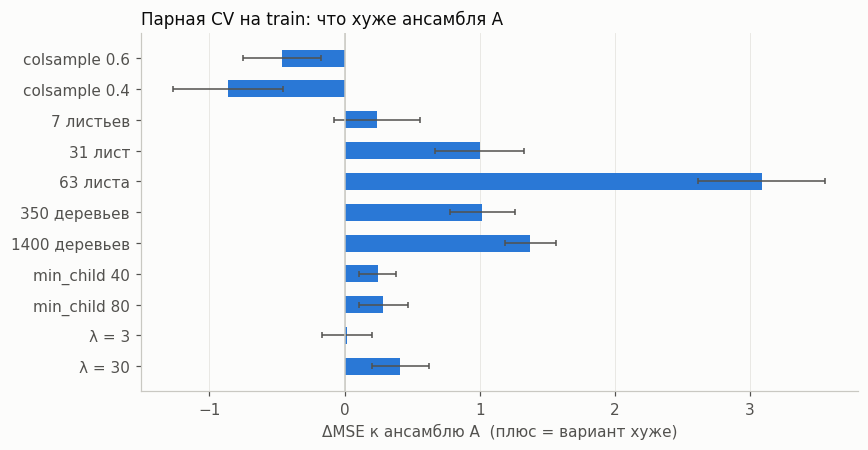

In [19]:
VARIANTS = {'ансамбль A (15 листьев, mcs 20, λ 10, colsample 1.0, 700 деревьев)': {}, 'colsample 0.6': dict(colsample_bytree=0.6), 'colsample 0.4': dict(colsample_bytree=0.4),
    '7 листьев': dict(num_leaves=7), '31 лист': dict(num_leaves=31), '63 листа': dict(num_leaves=63), '350 деревьев': dict(n_estimators=350),
    '1400 деревьев': dict(n_estimators=1400), 'min_child 40': dict(min_child_samples=40), 'min_child 80': dict(min_child_samples=80),
    'λ = 3': dict(reg_lambda=3), 'λ = 30': dict(reg_lambda=30)}
t0 = time.time(); err = {k: np.zeros(len(y)) for k in VARIANTS}
for a, b in KFold(5, shuffle=True, random_state=2026).split(Xf):
    for k, upd in VARIANTS.items():
        pr = dict(PARAMS); pr.update(upd)
        err[k][b] = (lgb.LGBMRegressor(**pr, random_state=0).fit(Xf.iloc[a], y[a]).predict(Xf.iloc[b]) - y[b]) ** 2
base_k = list(VARIANTS)[0]; rows = []
for k, e in err.items():
    d = e - err[base_k]; rows.append((k, np.sqrt(e.mean()), d.mean(), d.std() / np.sqrt(len(y))))
H = pd.DataFrame(rows, columns=['вариант', 'CV RMSE', 'ΔMSE к A', 'SE']).iloc[1:]
display(H.round(3).reset_index(drop=True)); print('время: %.0f с' % (time.time() - t0))
fig, ax = plt.subplots(figsize=(8, 4.2)); H2 = H.iloc[::-1]
ax.barh(H2['вариант'], H2['ΔMSE к A'], xerr=H2['SE'], color=BLUE, height=0.55, error_kw=dict(ecolor=MUTED, lw=1, capsize=2))
ax.axvline(0, color='#c9c8c2', lw=1); ax.set_xlabel('ΔMSE к ансамблю A  (плюс = вариант хуже)'); ax.grid(axis='y', visible=False)
ax.set_title('Парная CV на train: что хуже ансамбля A'); plt.tight_layout(); plt.show()

**Что подтверждается на train:** 31/63 листа, 1400 деревьев и λ = 30 хуже финальной конфигурации; 7 листьев, `min_child` и λ = 3 — в пределах шума.
**Что не подтверждается:** по `colsample` train-CV предпочитает 0.6 (лучше финального значения 1.0), а на открытом тесте 1.0 оказалось заметно лучше — см. таблицу ниже.
Возможное объяснение — разная чистота меток train и теста (на train шум ≈ 10 RMSE, на тесте RMSE лучших решений ≈ 1.2); это допущение, а не проверенный факт.

## 7. Результаты на открытом тесте (оценки платформы) и итог
Шкала: RMSE = 7 → 0 баллов, RMSE = 0 → 100. Выбор значений гиперпараметров в строках 4–9 опирался на эти оценки (закрытый тест для настройки не использовался).

| # | Гипотеза | Балл на открытом тесте | Вывод |
|---|---|---|---|
| 1 | Ridge на logit-шкале, прогноз E[σ(f+ε)] | 60.2 | лучший на train-CV, но на тесте слабее бустинга |
| 2 | Смесь «линейная + бустинг» 50/50 | 72.4 | линейная часть вредит |
| 3 | CatBoost / LightGBM (d6, 3σ-чистка, ×3 сида) | 70.9 / 80.7 | LightGBM лучше |
| 4 | Чистка выбросов 3σ / 2σ / без | 78.2 / 74.2 / 79.2 | чистка вредит |
| 5 | 7 / 15 / 31 / 63 листа | 77.8 / 82.5 / 78.7 / 74.9 | оптимум ≈ 15 |
| 6 | LightGBM на logit-цели | 62.9 | шкала y лучше |
| 7 | colsample 0.4 / 0.6 / 1.0 | 79.1 / 82.5 / 84.0 | все признаки в каждом дереве |
| 8 | min_child 20 / 40 / 80; λ 30; 1400 деревьев | 83.5 / 82.5 / 82.5; 81.7; 78.7 | параметры близки к оптимуму |
| 9 | Сиды 3 → 30 (L0) | 82.5 → 83.65 | ансамблирование убирает шум обучения |
| 10 | 30 сидов, colsample 1.0: min_child 40 / 20 | 84.59 / 84.77 | ансамбль A = 84.77 |
| 11 | Смесь A (2/3) + B (1/3), B = colsample 0.6 (балл 83.65) | 85.17 — расчётная оценка, на платформе открытого теста смесь не отправлялась | см. ниже |

Оценка смеси на открытом тесте точная, а не «на глаз»: известны баллы A (84.77) и B (83.65) и расстояние между их предсказаниями, а для квадратичной ошибки смеси есть тождество
`MSE(w) = (1−w)·MSE_A + w·MSE_B − w(1−w)·‖p_A − p_B‖²/n`. Вес w = 1/3 близок к оптимуму (кривая плоская: 0.25 → 85.15, 1/3 → 85.17, 0.5 → 85.08).

In [15]:
# Проверка воспроизводимости и весов: веса из models/ дают ровно те же предсказания, что сохранённый файл
# import json, glob
# if os.path.exists('meta.json') and os.path.isdir('models'):
#     meta = json.load(open('meta.json')); Xt, _ = make_frame(te, meta['cat_maps']); Xt = Xt[meta['columns']]
#     ens = lambda p: np.mean([lgb.Booster(model_file=f).predict(Xt) for f in sorted(glob.glob(f'models/{p}_*.txt'))], 0)
#     pa, pb = ens('a'), ens('b'); blend = np.clip((1 - meta['w_b']) * pa + meta['w_b'] * pb, 0, 100)
#     print(f"веса: {len(glob.glob('models/a_*.txt'))} + {len(glob.glob('models/b_*.txt'))} моделей, seed {meta['seed']}, вес B = {meta['w_b']:.3f}")
#     ref = pd.read_csv(f"public/public_blend_seed{meta['seed']}.csv").protection_score.values
#     print('макс. |предсказание из весов − сохранённый файл| = %.5f' % np.abs(np.round(blend, 4) - ref).max())
#     print('RMS(A, B) на открытом тесте = %.3f' % np.sqrt(np.mean((pa - pb) ** 2)))
# else:
#     print('meta.json / models/ не найдены — запустите train.py')

### Итог
* Метки train зашумлены сильно (шум аддитивен на logit-шкале), поэтому абсолютный CV на train малоинформативен; сравнивать варианты приходится парно и по открытому тесту.
* Линейная модель на logit-шкале оптимальна для train, но на тесте уступает бустингу — структура у теста чище.
* Финальная модель — смесь двух ансамблей LightGBM на исходной шкале (A: все признаки в дереве, вес 2/3; B: 60% признаков, вес 1/3; по 30 сидов в каждом); веса сохраняются в `models/`.
* Открытые вопросы: расхождение train-CV и теста по `colsample`; устойчивость выбора на закрытом тесте проверить можно только на нём.